# 15 — Brain and skull CT segmentation benchmark

This is a **new, separate experiment**. The earlier 10-organ U-Net checkpoint has no brain/skull channels
and is not reused or counted as a brain/skull result.

The official TotalSegmentator train/validation split is preserved. Only cases with a nearly complete
brain and skull are selected (brain mask ≥800 mL, skull mask ≥300 mL). The official test split is never
opened. The source masks sometimes overlap; **skull takes priority** in the exclusive three-class target.

Models: a non-learning >300 HU skull threshold, a compact MONAI 3D U-Net, and MONAI 3D SegResNet.
The two learned models receive identical cropped CT inputs, augmentation, 96³ patches, Dice+CE loss,
optimizer, epoch budget, and full-volume validation. Each epoch saves `last.pt`; the highest validation
macro-Dice model is saved as `best.pt`.

The default 30-epoch run is a **development benchmark**, not a clinically validated model. Extend `MAX_EPOCHS`
and rerun to resume training from the saved checkpoints. The same 8 GB laptop GPU is used for both models.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import monai
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    raise RuntimeError("Run from the F:/csstdy project root")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.benchmark.brain_skull import (
    INPUT_CHANNELS,
    LABELS,
    load_or_create_inventory,
    make_model,
    prepare_inventory,
    predict_case,
    sha256_file,
    threshold_skull_baseline,
    train_model,
)

DATASET_ROOT = Path(
    os.environ.get("TOTALSEG_DATASET_ROOT", PROJECT_ROOT / "Totalsegmentator_dataset_v201")
).resolve()
MANIFEST_PATH = PROJECT_ROOT / "data" / "splits" / "dataset_manifest.json"
OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "brain_skull_benchmark"
CACHE_ROOT = PROJECT_ROOT / "data" / "cache" / "brain_skull_benchmark"
INVENTORY_PATH = OUTPUT_ROOT / "development_inventory.json"

MODELS = ("unet3d", "segresnet3d")
MAX_EPOCHS = 30  # Increasing this resumes existing checkpoints.
ROI = 96
SEED = 42

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is required for this benchmark; no CPU fallback")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch / MONAI:", torch.__version__, "/", monai.__version__)
print("Input channels:", INPUT_CHANNELS)
print("Labels:", LABELS)

F:\csstdy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


F:\csstdy\.venv\Lib\site-packages\torch\jit\_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


GPU: NVIDIA GeForce RTX 4060 Laptop GPU
PyTorch / MONAI: 2.14.0+cu130 / 1.6.0
Input channels: ('brain_window_-100_200_HU', 'bone_window_-300_1500_HU')
Labels: {0: 'background', 1: 'brain', 2: 'skull'}


## 1. Freeze the development cohort

The inventory scanner reads only the official train and validation masks. It does not resolve any test
file paths. An existing inventory is reused only when the manifest file hash matches.

In [2]:
inventory = load_or_create_inventory(DATASET_ROOT, MANIFEST_PATH, INVENTORY_PATH)
assert inventory["test_split_accessed"] is False
assert set(item["split"] for item in inventory["cases"]) == {"train", "val"}
display(pd.DataFrame([inventory["selected_counts"]]).rename(index={0: "selected complete-head cases"}))
print("Manifest SHA-256:", inventory["manifest_file_sha256"])
print("Overlap policy:", inventory["overlap_policy"])
print("Validation IDs:", [item["case_id"] for item in inventory["cases"] if item["split"] == "val"])

,train,val
selected complete-head cases,98,5


Manifest SHA-256: af365823dd2dbf05b56115420bfcfd3472016036b5477c479beaf5913b01959f
Overlap policy: skull wins; brain is removed where the two source masks overlap
Validation IDs: ['s0346', 's0792', 's0874', 's1161', 's1260']


## 2. Prepare identical CT inputs for all methods

Each case is cropped around its reference brain/skull masks for this controlled development benchmark.
The two channels are a brain window (−100 to 200 HU) and a bone window (−300 to 1500 HU). Cropping with
target masks is **not a deployable CT-only inference workflow**; future external evaluation must replace
it with a CT-only head crop. Original dataset files are never modified.

In [3]:
prepared = prepare_inventory(DATASET_ROOT, inventory, CACHE_ROOT)
assert all(item["split"] in {"train", "val"} for item in prepared)
val_records = [item for item in prepared if item["split"] == "val"]
print(f"Prepared {len(prepared)} cached cases ({len(val_records)} validation)")
print("Cache:", CACHE_ROOT)

Prepared 103 cached cases (5 validation)
Cache: F:\csstdy\data\cache\brain_skull_benchmark


## 3. Non-learning skull baseline

This >300 HU baseline predicts **skull only**. Brain Dice is not applicable, so it is not ranked by
two-class macro Dice against the learned models.

In [4]:
threshold_report = threshold_skull_baseline(val_records)
(OUTPUT_ROOT / "threshold_baseline.json").write_text(
    json.dumps(threshold_report, indent=2) + "\n", encoding="utf-8"
)
print("Skull threshold validation Dice:", round(threshold_report["skull_dice"], 4))

Skull threshold validation Dice: 0.7919


## 4. Train and save the 3D U-Net and SegResNet

Training resumes from `last.pt` when an identical data/model contract exists. The best checkpoint is
selected on validation macro Dice only. No official test images or labels are accessed.

In [5]:
inventory_sha256 = sha256_file(INVENTORY_PATH)
model_reports = {}
for model_name in MODELS:
    print(f"\n=== {model_name} ===", flush=True)
    model_reports[model_name] = train_model(
        model_name,
        prepared,
        OUTPUT_ROOT,
        inventory_sha256=inventory_sha256,
        max_epochs=MAX_EPOCHS,
        roi=ROI,
        seed=SEED,
    )
    assert model_reports[model_name]["test_split_accessed"] is False
    print("Best checkpoint:", model_reports[model_name]["best_checkpoint"])


=== unet3d ===


Best checkpoint: F:\csstdy\outputs\brain_skull_benchmark\unet3d\best.pt

=== segresnet3d ===


Best checkpoint: F:\csstdy\outputs\brain_skull_benchmark\segresnet3d\best.pt


## 5. Validation comparison and training curves

Dice assesses overlap; HD95 (mm) assesses boundary error. Runtime and checkpoint hashes are retained in
the generated reports. These are **development validation** scores, not locked-test scores.

,Method,Best epoch,Brain Dice,Skull Dice,Macro Dice,Brain HD95 (mm),Skull HD95 (mm)
0,HU threshold (skull only),—,—,0.7919,—,—,—
1,unet3d,28.0000,0.9649,0.9313,0.9481,62.3824,9.9870
2,segresnet3d,27.0000,0.9887,0.9544,0.9715,1.6243,1.6243


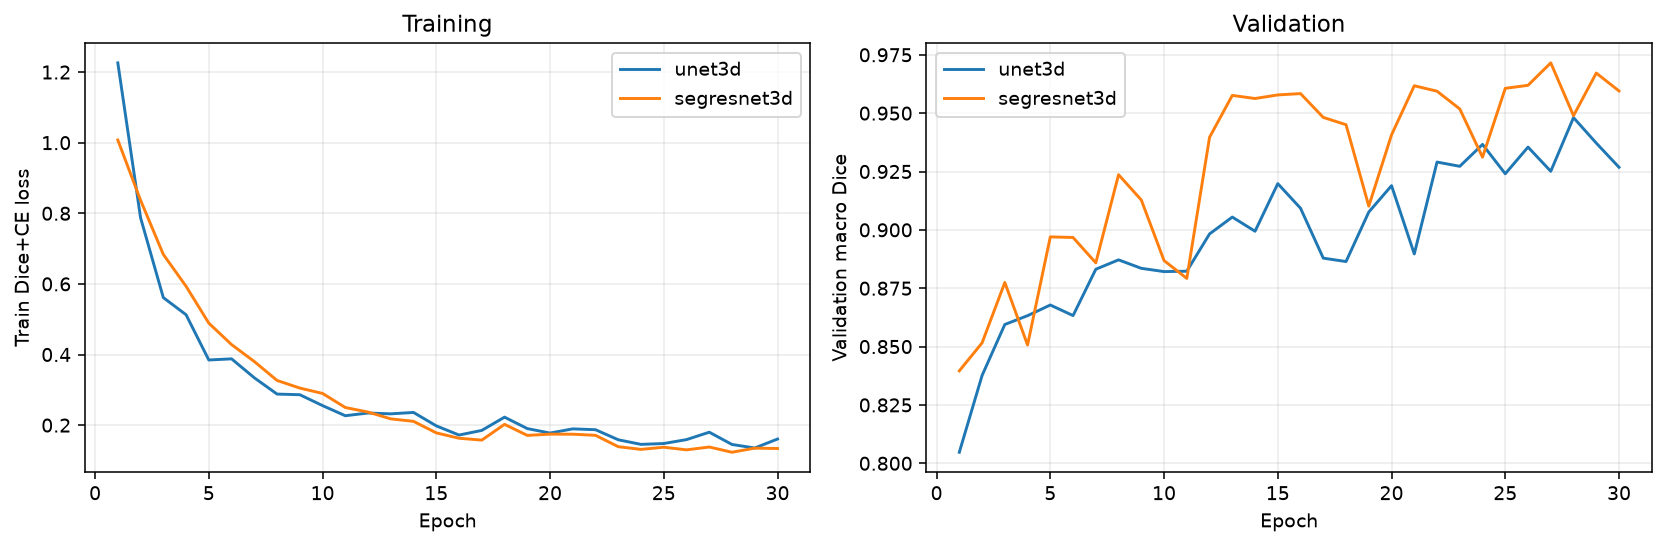

In [6]:
rows = [
    {
        "Method": "HU threshold (skull only)",
        "Best epoch": None,
        "Brain Dice": None,
        "Skull Dice": threshold_report["skull_dice"],
        "Macro Dice": None,
        "Brain HD95 (mm)": None,
        "Skull HD95 (mm)": None,
    }
]
for model_name, report in model_reports.items():
    validation = report["validation"]
    rows.append(
        {
            "Method": model_name,
            "Best epoch": report["selected_epoch"],
            "Brain Dice": validation["mean_dice"]["brain"],
            "Skull Dice": validation["mean_dice"]["skull"],
            "Macro Dice": validation["macro_mean_dice"],
            "Brain HD95 (mm)": validation["mean_hd95_mm"]["brain"],
            "Skull HD95 (mm)": validation["mean_hd95_mm"]["skull"],
        }
    )
comparison = pd.DataFrame(rows)
comparison.to_csv(OUTPUT_ROOT / "comparison.csv", index=False)
display(comparison.style.format(precision=4, na_rep="—"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=140)
for model_name in MODELS:
    history = json.loads((OUTPUT_ROOT / model_name / "history.json").read_text(encoding="utf-8"))
    axes[0].plot([row["epoch"] for row in history], [row["train_loss"] for row in history], label=model_name)
    axes[1].plot([row["epoch"] for row in history], [row["validation_macro_dice"] for row in history], label=model_name)
axes[0].set(xlabel="Epoch", ylabel="Train Dice+CE loss", title="Training")
axes[1].set(xlabel="Epoch", ylabel="Validation macro Dice", title="Validation")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "learning_curves.png", bbox_inches="tight")
plt.show()

## 6. Visual check on a validation head CT

Red contours are the reference masks; cyan contours are predictions from each best checkpoint. This
checks that the metric reflects sensible anatomy and reveals stray islands that can inflate HD95.

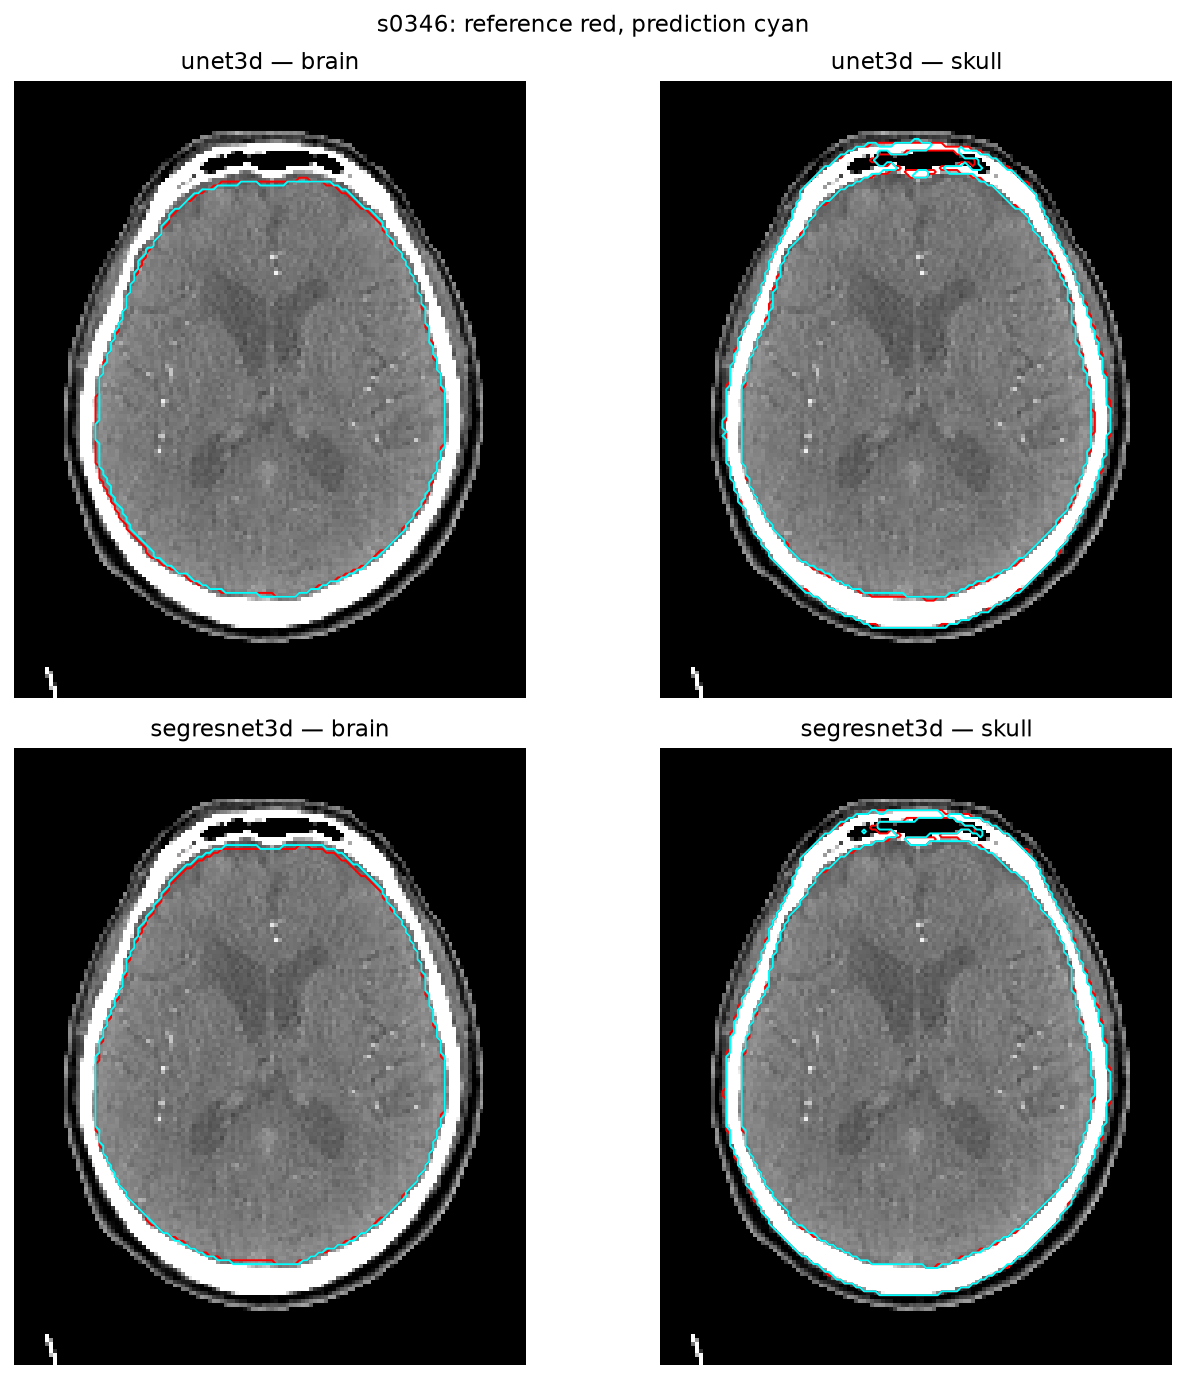

In [7]:
example = next(item for item in val_records if item["case_id"] == "s0346")
image = np.load(example["image_path"], mmap_mode="r")[0]
truth = np.load(example["label_path"], mmap_mode="r")
center = np.rint(np.argwhere(truth == 1).mean(axis=0)).astype(int)
fig, axes = plt.subplots(2, 2, figsize=(10, 10), dpi=140)
for row, model_name in enumerate(MODELS):
    checkpoint = torch.load(model_reports[model_name]["best_checkpoint"], map_location="cpu", weights_only=True)
    model = make_model(model_name).cuda()
    model.load_state_dict(checkpoint["model_state"])
    model.eval()
    prediction = predict_case(model, example, device=torch.device("cuda"), roi=ROI)
    for col, class_id in enumerate((1, 2)):
        axis = axes[row, col]
        axis.imshow(image[:, :, center[2]].T, cmap="gray", vmin=0, vmax=1, origin="lower")
        axis.contour((truth[:, :, center[2]] == class_id).T, levels=[0.5], colors="red", linewidths=1)
        axis.contour((prediction[:, :, center[2]] == class_id).T, levels=[0.5], colors="cyan", linewidths=1)
        axis.set_title(f"{model_name} — {LABELS[class_id]}")
        axis.axis("off")
    del model
fig.suptitle("s0346: reference red, prediction cyan")
fig.tight_layout()
overlay_path = OUTPUT_ROOT / "validation_overlay_s0346.png"
fig.savefig(overlay_path, bbox_inches="tight")
plt.show()

## 7. Reuse the saved benchmark models

The best files contain the model weights, model/data contract, validation summary, optimizer state, and
epoch. Loading is restricted to weights-only deserialization. A separate new-patient inference workflow
must use a CT-derived crop; this notebook deliberately uses reference masks to define its development
crop and should not be represented as independent external validation.

In [8]:
for model_name, report in model_reports.items():
    checkpoint_path = Path(report["best_checkpoint"])
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    assert checkpoint["contract_sha256"] == report["contract_sha256"]
    reloaded_model = make_model(model_name)
    reloaded_model.load_state_dict(checkpoint["model_state"])
    reloaded_model.eval()
    print(
        model_name,
        "| best epoch", checkpoint["epoch"],
        "| SHA-256", report["best_checkpoint_sha256"],
    )
    del reloaded_model
display(Markdown(
    "**Saved benchmark:** `outputs/brain_skull_benchmark/`  \n"
    "**Train/validation only:** the official test split remained locked."
))

unet3d | best epoch 28 | SHA-256 790c1412e5e5c9de471a4cc0d00b0ca19f8b878f8c74bc6da429761c53952d5d
segresnet3d | best epoch 27 | SHA-256 fd5bfcc59c7d7d6cd574b606366925b8c72f90f568590bf99a3a8a93d1610a9f


**Saved benchmark:** `outputs/brain_skull_benchmark/`  
**Train/validation only:** the official test split remained locked.